Dataset shape: (1800, 18)
   product_id        date category  opening_stock  units_received  units_sold  \
0        1001  2026-04-01    Dairy             27               0           6   
1        1001  2026-04-02    Dairy             30              12           5   
2        1001  2026-04-03    Dairy             38               0          14   
3        1001  2026-04-04    Dairy             49               0          11   
4        1001  2026-04-05    Dairy             19              13          12   

   unit_price  discount_pct  days_to_expiry  temperature_c  waste_units  \
0        32.0           0.0               1            4.1            0   
1        32.0           0.0               5            3.7            0   
2        32.0           0.0               2            4.6            0   
3        32.0           0.0               0            5.7            0   
4        32.0           0.0               0            3.0            0   

   stockout_flag  day_of_week  month


Discount Model Results
----------------------
MAE: 0.0
RMSE: 0.0
R2 Score: 1.0

Saved: ml/outputs/discount_predictions.csv
Saved: ml/models/discount_model.pkl
Saved: ml/models/discount_features.pkl


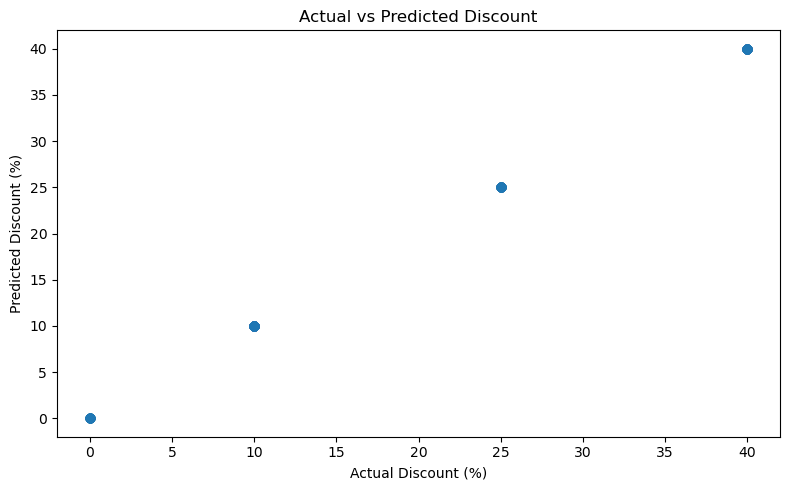


Feature Importance:
days_to_expiry           0.546497
expiry_urgency           0.453503
product_id               0.000000
stockout_flag            0.000000
sales_rate               0.000000
remaining_after_sales    0.000000
stock_available          0.000000
month                    0.000000
day_of_week              0.000000
waste_units              0.000000
category                 0.000000
temperature_c            0.000000
discount_pct             0.000000
unit_price               0.000000
units_sold               0.000000
units_received           0.000000
opening_stock            0.000000
day                      0.000000
dtype: float64


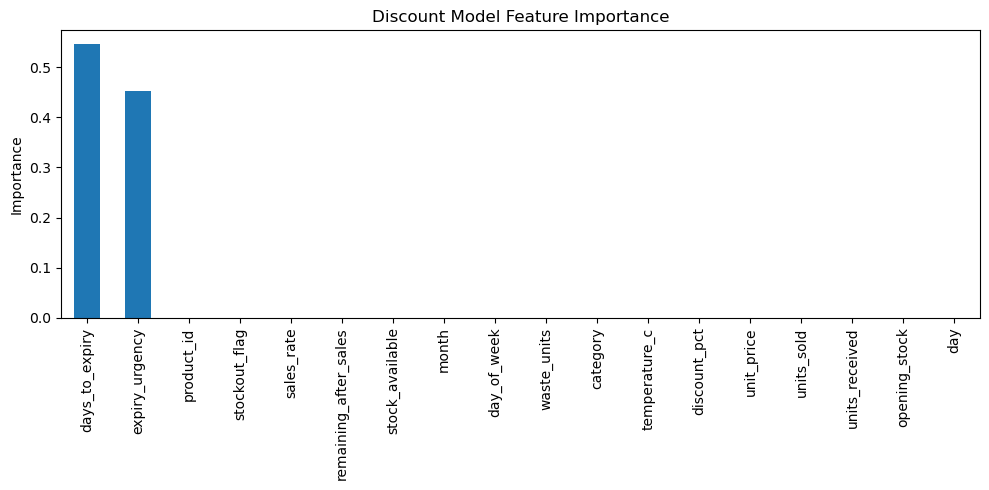


Sample Predictions:
   actual_discount  predicted_discount
0               40                40.0
1               10                10.0
2               40                40.0
3               10                10.0
4                0                 0.0
5               10                10.0
6               10                10.0
7               40                40.0
8               40                40.0
9               10                10.0


In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data_path = r"ml\data\processed\perishable_features.csv"

if not os.path.exists(data_path):
    data_path = r"..\data\processed\perishable_features.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

df.columns = df.columns.str.strip()

possible_targets = [
    "discount_percentage",
    "discount_percent",
    "recommended_discount",
    "discount"
]

target = next((col for col in possible_targets if col in df.columns), None)

if target is None:
    df["recommended_discount"] = 0.0

    if "days_to_expiry" in df.columns:
        days = pd.to_numeric(df["days_to_expiry"], errors="coerce")
        df["recommended_discount"] = np.select(
            [days <= 1, days <= 3, days <= 7],
            [40, 25, 10],
            default=0
        )
    elif "expiry_urgency" in df.columns:
        urgency = pd.to_numeric(df["expiry_urgency"], errors="coerce")
        df["recommended_discount"] = np.clip(urgency * 40, 0, 40)
    else:
        raise ValueError(
            "Dataset needs days_to_expiry or expiry_urgency "
            "to create a demonstration discount target."
        )

    target = "recommended_discount"

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["day"] = df["date"].dt.day
    df["month"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek
    df = df.drop(columns=["date"])

if "expiry_date" in df.columns:
    df = df.drop(columns=["expiry_date"])

if "product_id" in df.columns:
    df["product_id"] = df["product_id"].astype(str)

for col in df.columns:
    if col != target and df[col].dtype == "object":
        df[col] = df[col].astype("category").cat.codes

df = df.replace([np.inf, -np.inf], np.nan)

feature_columns = [col for col in df.columns if col != target]

for col in feature_columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

X = df[feature_columns]
y = df[target]

if len(df) < 5:
    raise ValueError("Not enough rows to train the discount model.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

model.fit(X_train, y_train)

predictions = np.clip(model.predict(X_test), 0, 60)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions) if len(y_test) > 1 else float("nan")

print("\nDiscount Model Results")
print("----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

results = pd.DataFrame({
    "actual_discount": y_test.values,
    "predicted_discount": predictions
})

os.makedirs("ml/outputs", exist_ok=True)
os.makedirs("ml/models", exist_ok=True)

results.to_csv("ml/outputs/discount_predictions.csv", index=False)

joblib.dump(model, "ml/models/discount_model.pkl")
joblib.dump(feature_columns, "ml/models/discount_features.pkl")

print("\nSaved: ml/outputs/discount_predictions.csv")
print("Saved: ml/models/discount_model.pkl")
print("Saved: ml/models/discount_features.pkl")

plt.figure(figsize=(8, 5))
plt.scatter(y_test, predictions)
plt.xlabel("Actual Discount (%)")
plt.ylabel("Predicted Discount (%)")
plt.title("Actual vs Predicted Discount")
plt.tight_layout()
plt.show()

importance = pd.Series(
    model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Discount Model Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

print("\nSample Predictions:")
print(results.head(10))
